# Machine Learning Supervisado — Regresión Logística y Clasificación
**Universidad de Cundinamarca — Esp. Inteligencia Artificial**
**CADI – Introducción a Machine Learning — Periodo 2026-2**
Docente: Ing. Wilson Rojas Reales, PhD(c)

> Repositorio: https://github.com/Yohann0011/ml-supervisado-clasificacion-ucundinamarca
> Este notebook se ejecuta de extremo a extremo en **Google Colab** (runtime CPU).

# Notebook 01 — Predicción de defectos en producción (XYZ Inc.)

**Objetivo:** predecir si un lote será defectuoso (1) o no (0) con temperatura, presión,
velocidad, horas de operación y vibración; comparar Regresión Logística, Árbol de Decisión,
Random Forest, SVM, KNN y Naive Bayes con precisión, recall, F1, especificidad, AUC-ROC,
matriz de confusión, umbral de decisión y análisis de costos.


In [1]:
try:
    import google.colab  # noqa
    EN_COLAB = True
    !git clone --depth 1 https://github.com/Yohann0011/ml-supervisado-clasificacion-ucundinamarca repo 2>/dev/null
    import os
    if os.path.isdir('repo'): os.chdir('repo')
except Exception:
    EN_COLAB = False

import os, sys
from pathlib import Path
RAIZ = Path(os.environ.get('RAIZ_ML', '.'))
for p in (str(RAIZ), str(RAIZ / 'src')):
    if p not in sys.path:
        sys.path.insert(0, p)

%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from config import SEED, DIR_DATA, DIR_FIGS
print('Semilla:', SEED, '| datos en:', DIR_DATA)


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


Semilla: 42 | datos en: /tmp/arena/tenants/e8826d75-4142-4def-a7d6-6372192c98b1/sessions/36353820-3eae-42c9-a669-90aac76b7923/workspace/ml_informe/../ml_informe/data


## 1. Carga de datos y análisis exploratorio

In [2]:
df = pd.read_csv(DIR_DATA / 'caso_produccion.csv')
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
lote,1500.0,750.50,433.16,1.0,375.75,750.50,1125.25,1500.00
temperatura,1500.0,83.83,3.47,73.1,81.50,83.80,86.30,94.10
presion,1500.0,123.22,9.32,83.8,117.10,123.50,129.60,154.30
velocidad,1500.0,98.63,12.08,61.8,90.90,97.70,107.30,138.80
horas_operacion,1500.0,12.24,6.85,0.5,6.20,12.10,18.32,24.00
vibracion,1500.0,1.65,0.60,0.1,1.26,1.67,2.08,4.27
defectuoso,1500.0,0.18,0.38,0.0,0.00,0.00,0.00,1.00


defectuoso
0    0.8227
1    0.1773
Name: proportion, dtype: float64


/tmp/ipykernel_22440/2943405855.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df.defectuoso, palette=['#4C9F70','#D1495B'])


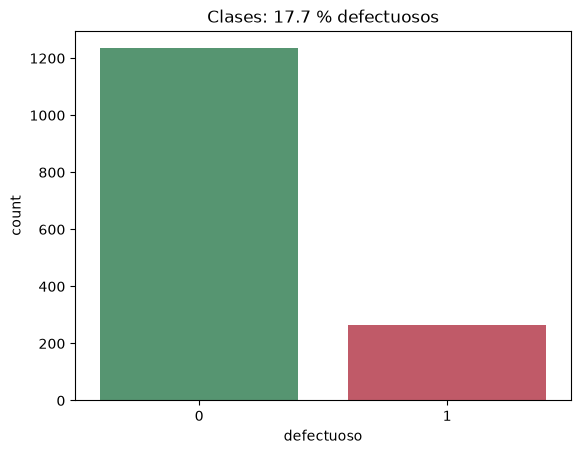

In [3]:
print(df.defectuoso.value_counts(normalize=True).round(4))
sns.countplot(x=df.defectuoso, palette=['#4C9F70','#D1495B'])
plt.title('Clases: 17.7 % defectuosos')
plt.show()

## 2. Entrenamiento y evaluación (partición 80/20 estratificada, semilla 42)

In [4]:
from analisis import ejecutar_caso
res = ejecutar_caso('Producción', df, 'defectuoso', {0: 'No defectuoso', 1: 'Defectuoso'}, 'prod')


##########################################################################
# CASO: Producción
# n = 1500 | variables = 5 | clase positiva = 17.73%
##########################################################################
Train: (1200, 5) (positivos 17.75%) | Test: (300, 5) (positivos 17.67%)
Línea base (clase mayoritaria = 0): accuracy = 0.8233


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k
OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k
OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k
OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k



>>> Regresión Logística
    Acc=0.770 Prec=0.417 Rec=0.755 F1=0.537 AUC=0.843 AP=0.578 Esp=0.773 MCC=0.432
    CM [TN=191 FP=56 FN=13 TP=40] | CV-F1=0.584±0.036 | gap overfitting=+0.023

>>> Árbol de Decisión
    Acc=0.810 Prec=0.455 Rec=0.377 F1=0.412 AUC=0.640 AP=0.281 Esp=0.903 MCC=0.302
    CM [TN=223 FP=24 FN=33 TP=20] | CV-F1=0.486±0.052 | gap overfitting=+0.190



>>> Random Forest
    Acc=0.837 Prec=0.536 Rec=0.566 F1=0.550 AUC=0.854 AP=0.557 Esp=0.895 MCC=0.451
    CM [TN=221 FP=26 FN=23 TP=30] | CV-F1=0.598±0.040 | gap overfitting=+0.163


...

    [GridSearch] Regresión Logística: {'clf__C': 1} -> F1_cv=0.584 | F1_test=0.537 Rec=0.755 AUC=0.843


    [GridSearch] Árbol de Decisión: {'clf__max_depth': 3, 'clf__min_samples_leaf': 20} -> F1_cv=0.565 | F1_test=0.478 Rec=0.604 AUC=0.780


    [GridSearch] Random Forest: {'clf__max_depth': 6, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100} -> F1_cv=0.633 | F1_test=0.527 Rec=0.641 AUC=0.854


    [GridSearch] SVM: {'clf__C': 50, 'clf__gamma': 0.01} -> F1_cv=0.617 | F1_test=0.573 Rec=0.774 AUC=0.871


    [GridSearch] KNN: {'clf__n_neighbors': 7} -> F1_cv=0.539 | F1_test=0.405 Rec=0.321 AUC=0.827
    [GridSearch] Naive Bayes: {'clf__var_smoothing': 1e-09} -> F1_cv=0.645 | F1_test=0.550 Rec=0.566 AUC=0.859


In [5]:
res.tabla_metricas().round(3)

,Modelo,Accuracy,Bal. Acc.,Precision,Recall,F1-Score,Especificidad,AUC-ROC,AP (PR-AUC),Acc. train,Acc. CV-5,σ CV
0,SVM,0.813,0.790,0.482,0.755,0.588,0.826,0.859,0.567,0.841,0.613,0.037
1,Random Forest,0.837,0.730,0.536,0.566,0.550,0.895,0.854,0.558,0.999,0.598,0.040
2,Naive Bayes,0.837,0.730,0.536,0.566,0.550,0.895,0.859,0.600,0.872,0.645,0.028
3,Regresión Logística,0.770,0.764,0.417,0.755,0.537,0.773,0.843,0.578,0.793,0.584,0.036
4,Árbol de Decisión,0.810,0.640,0.454,0.377,0.412,0.903,0.640,0.282,1.000,0.486,0.052
5,KNN,0.837,0.619,0.577,0.283,0.380,0.956,0.848,0.540,1.000,0.530,0.032


## 3. Figuras del experimento (ROC, PR, confusión, importancia, umbrales, costos)

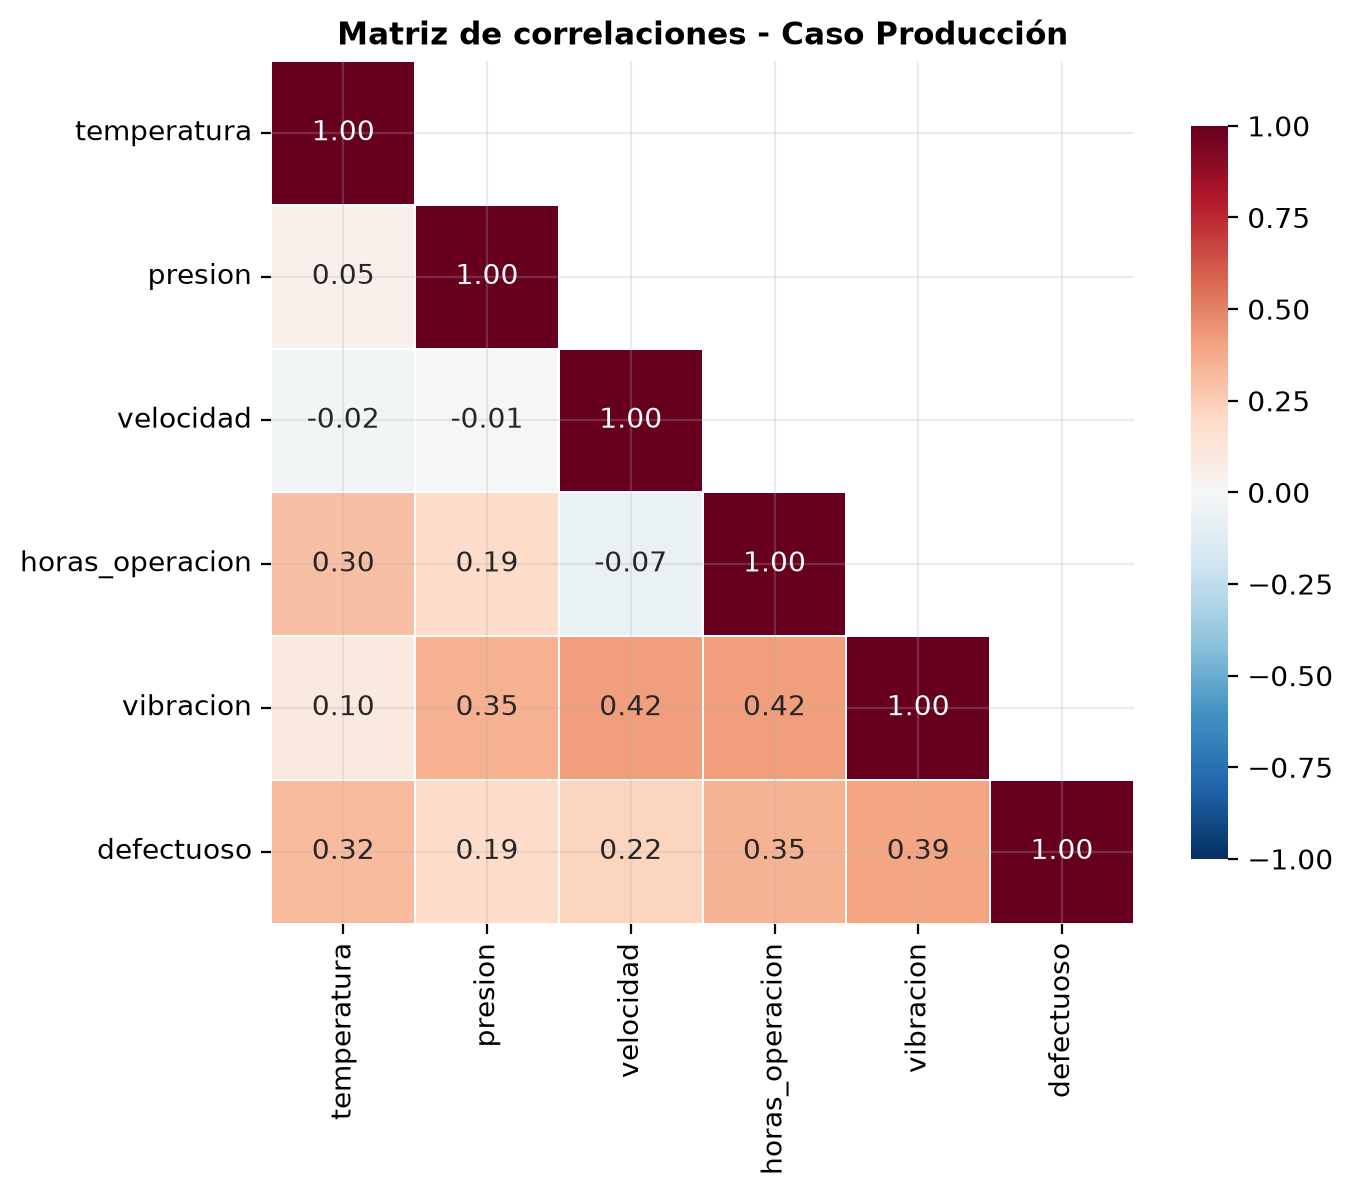

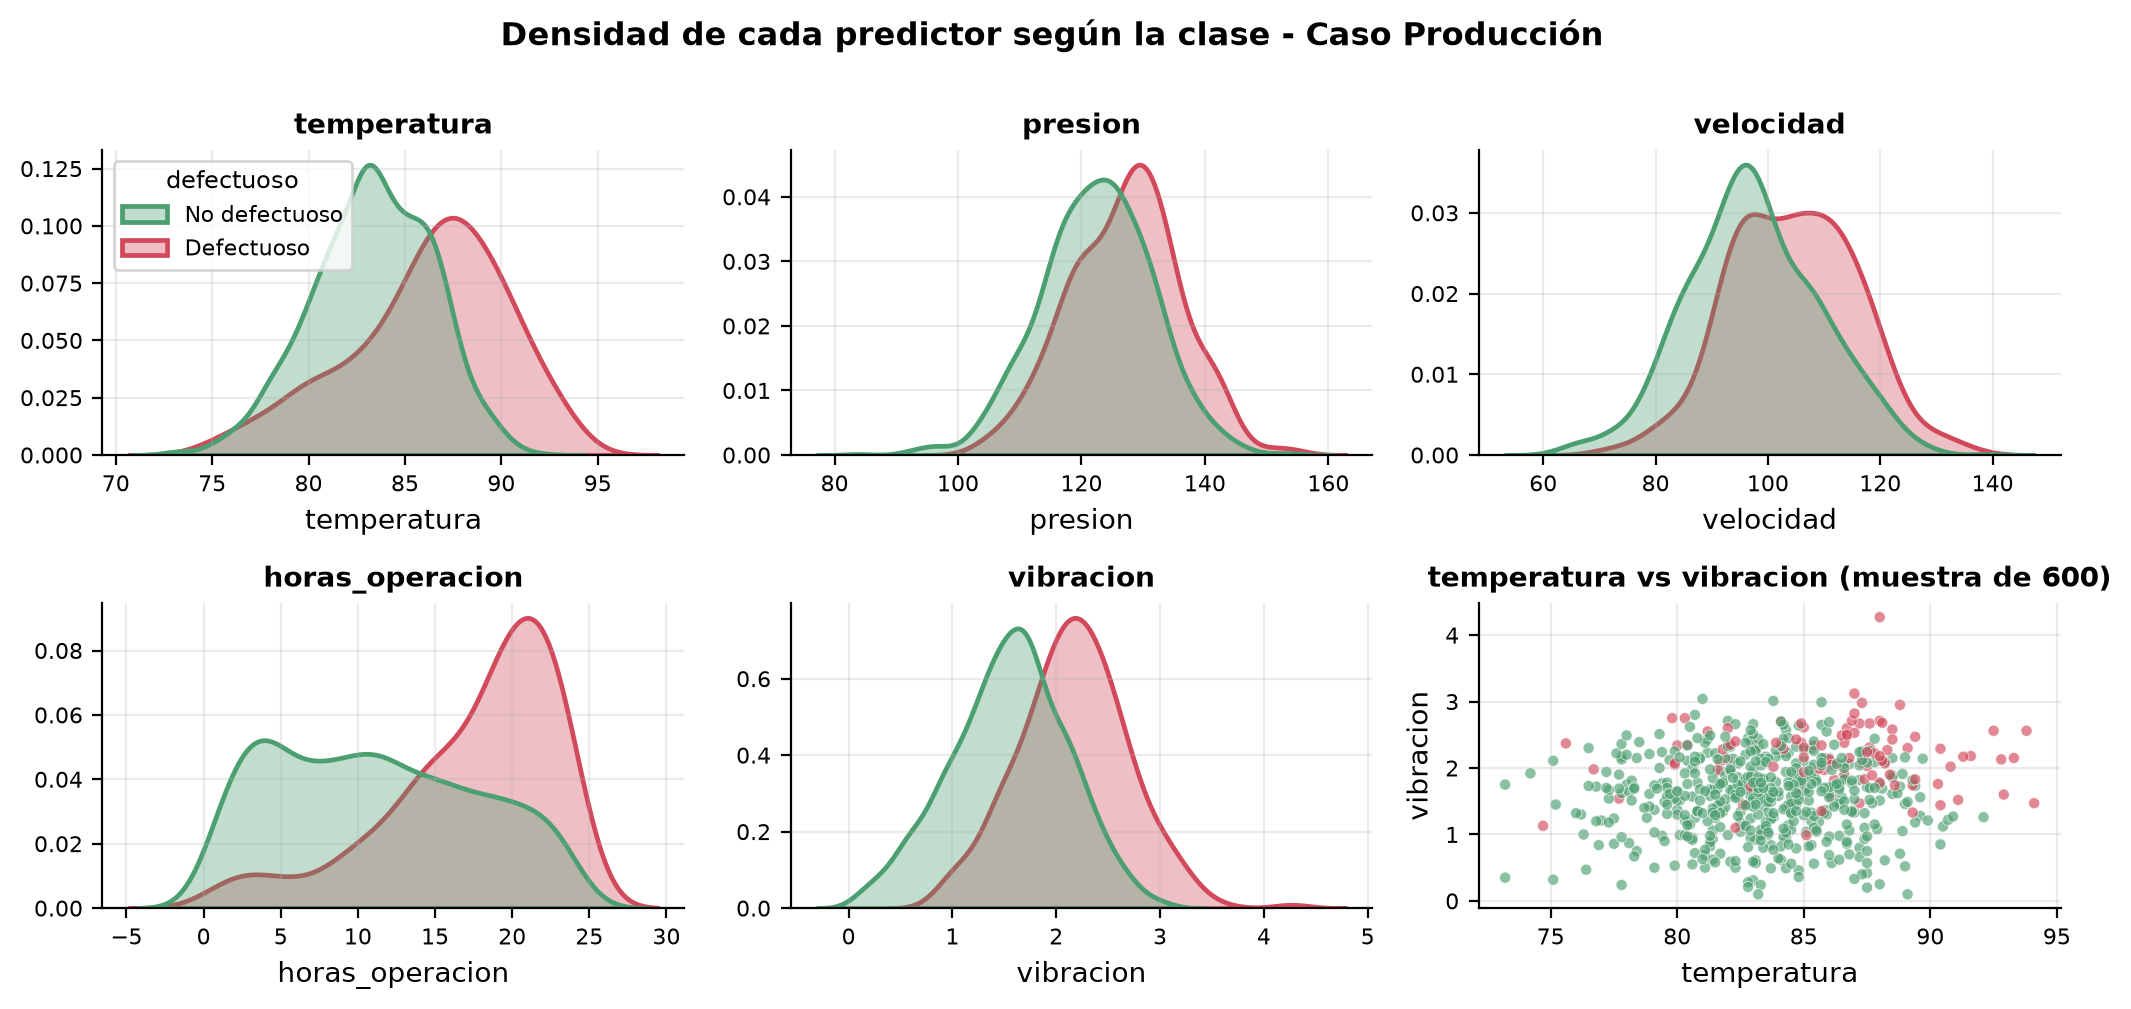

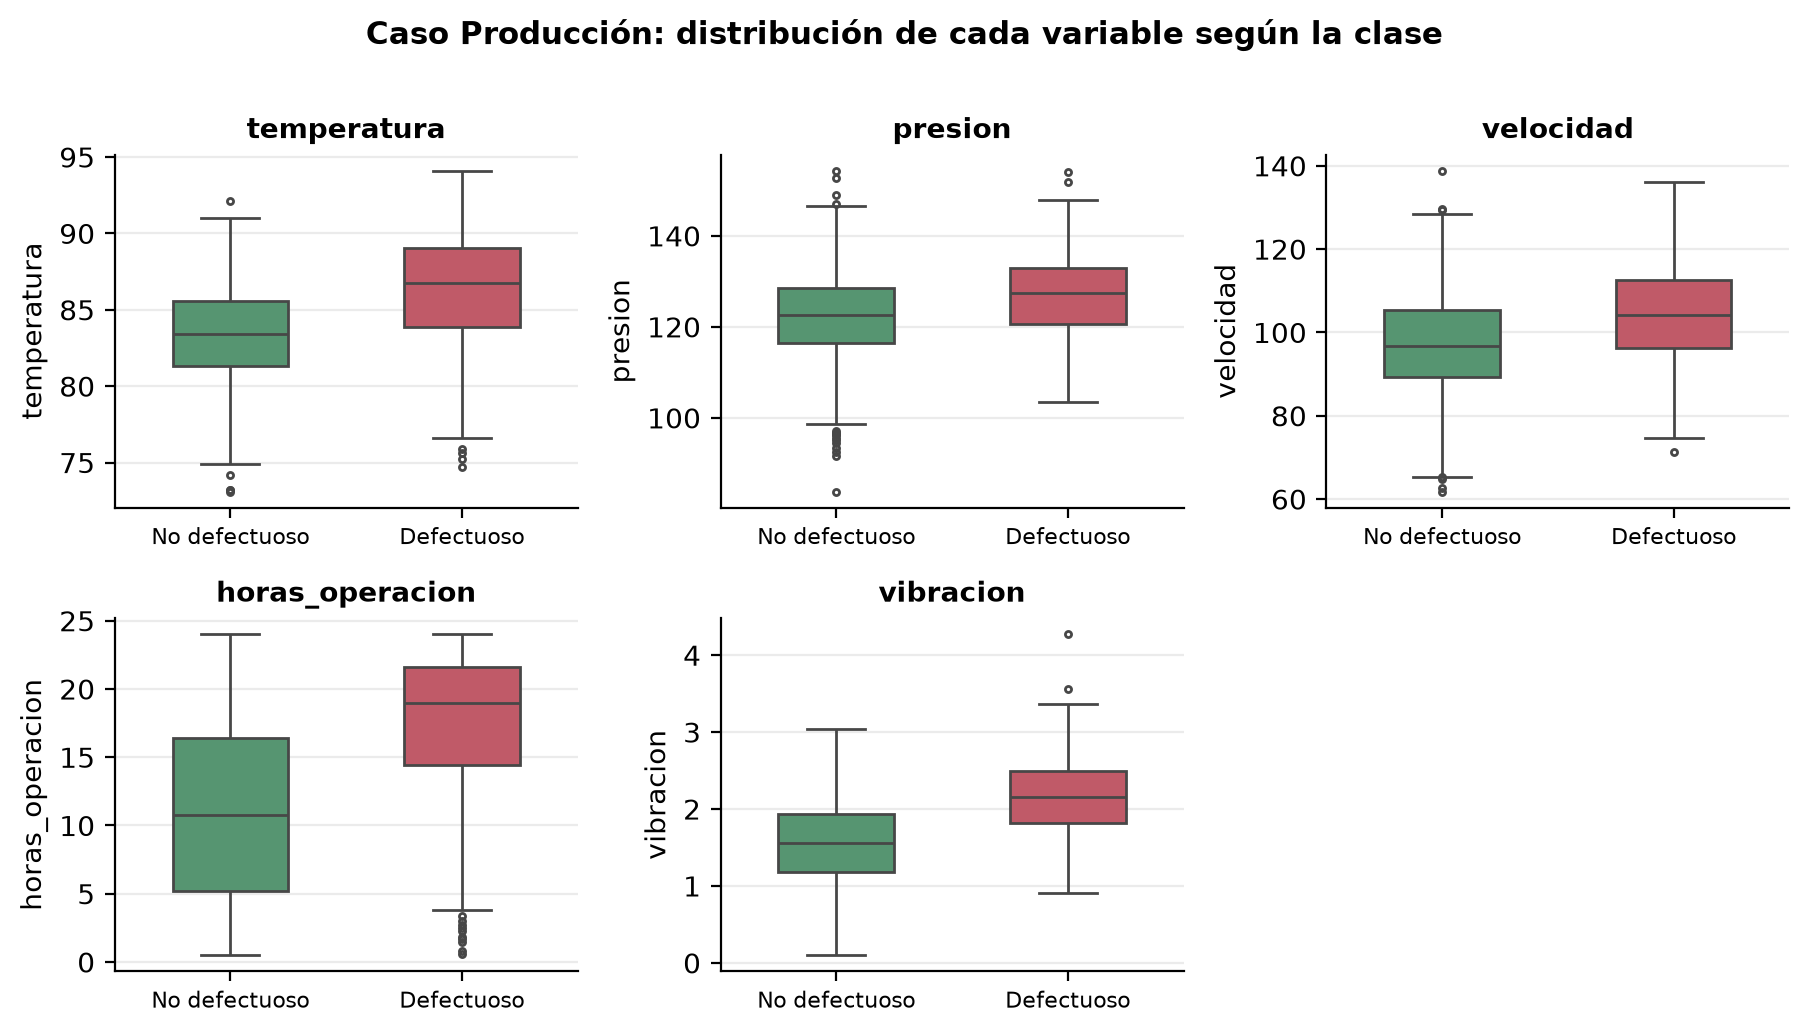

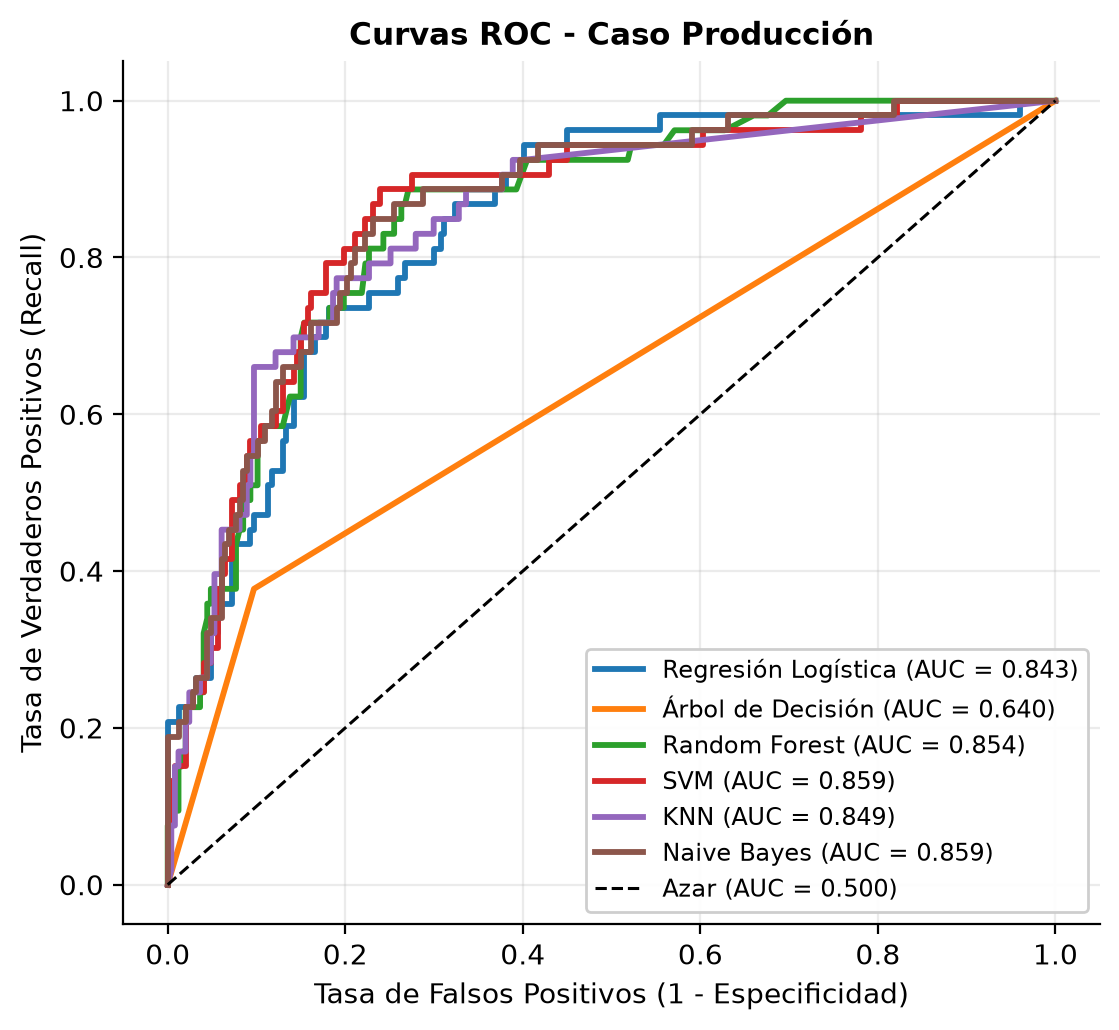

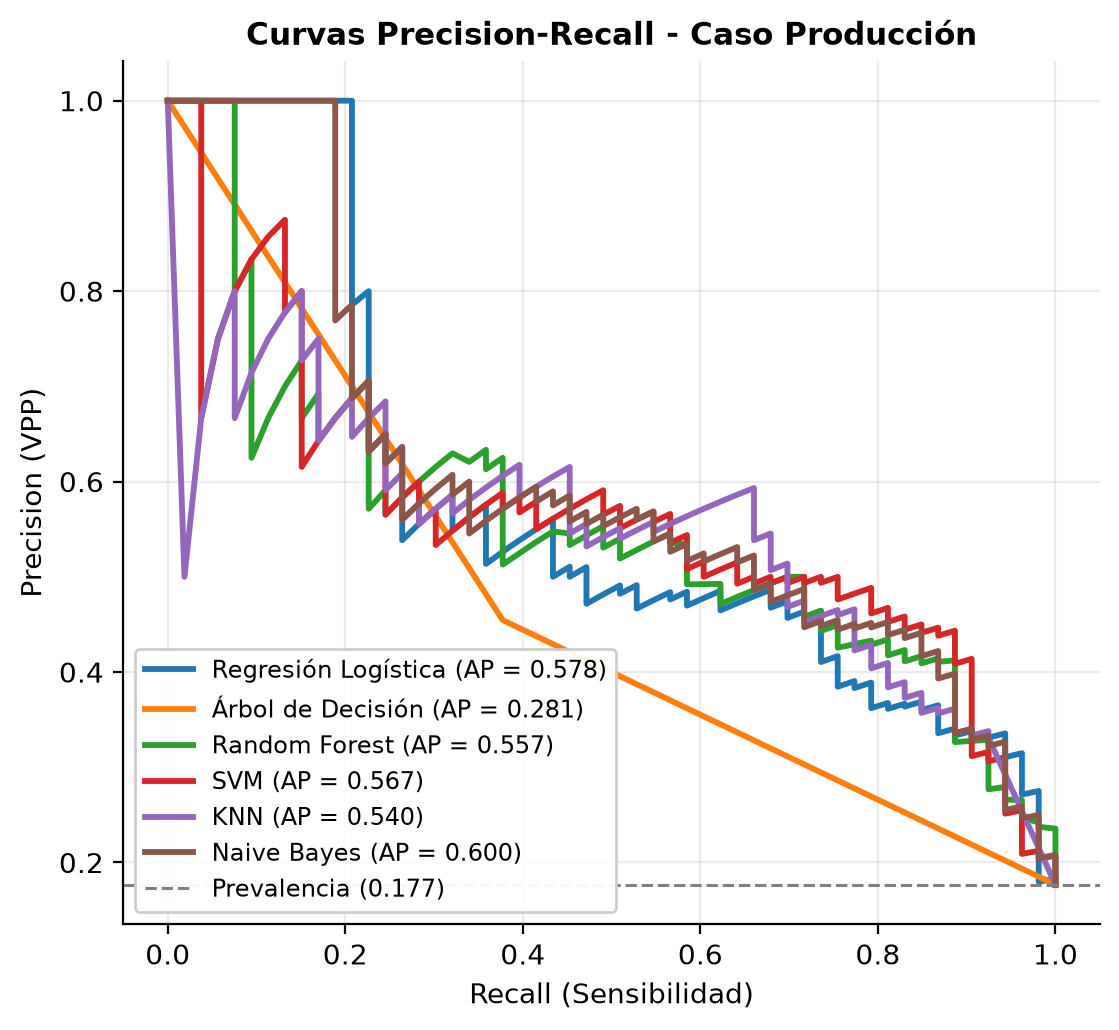

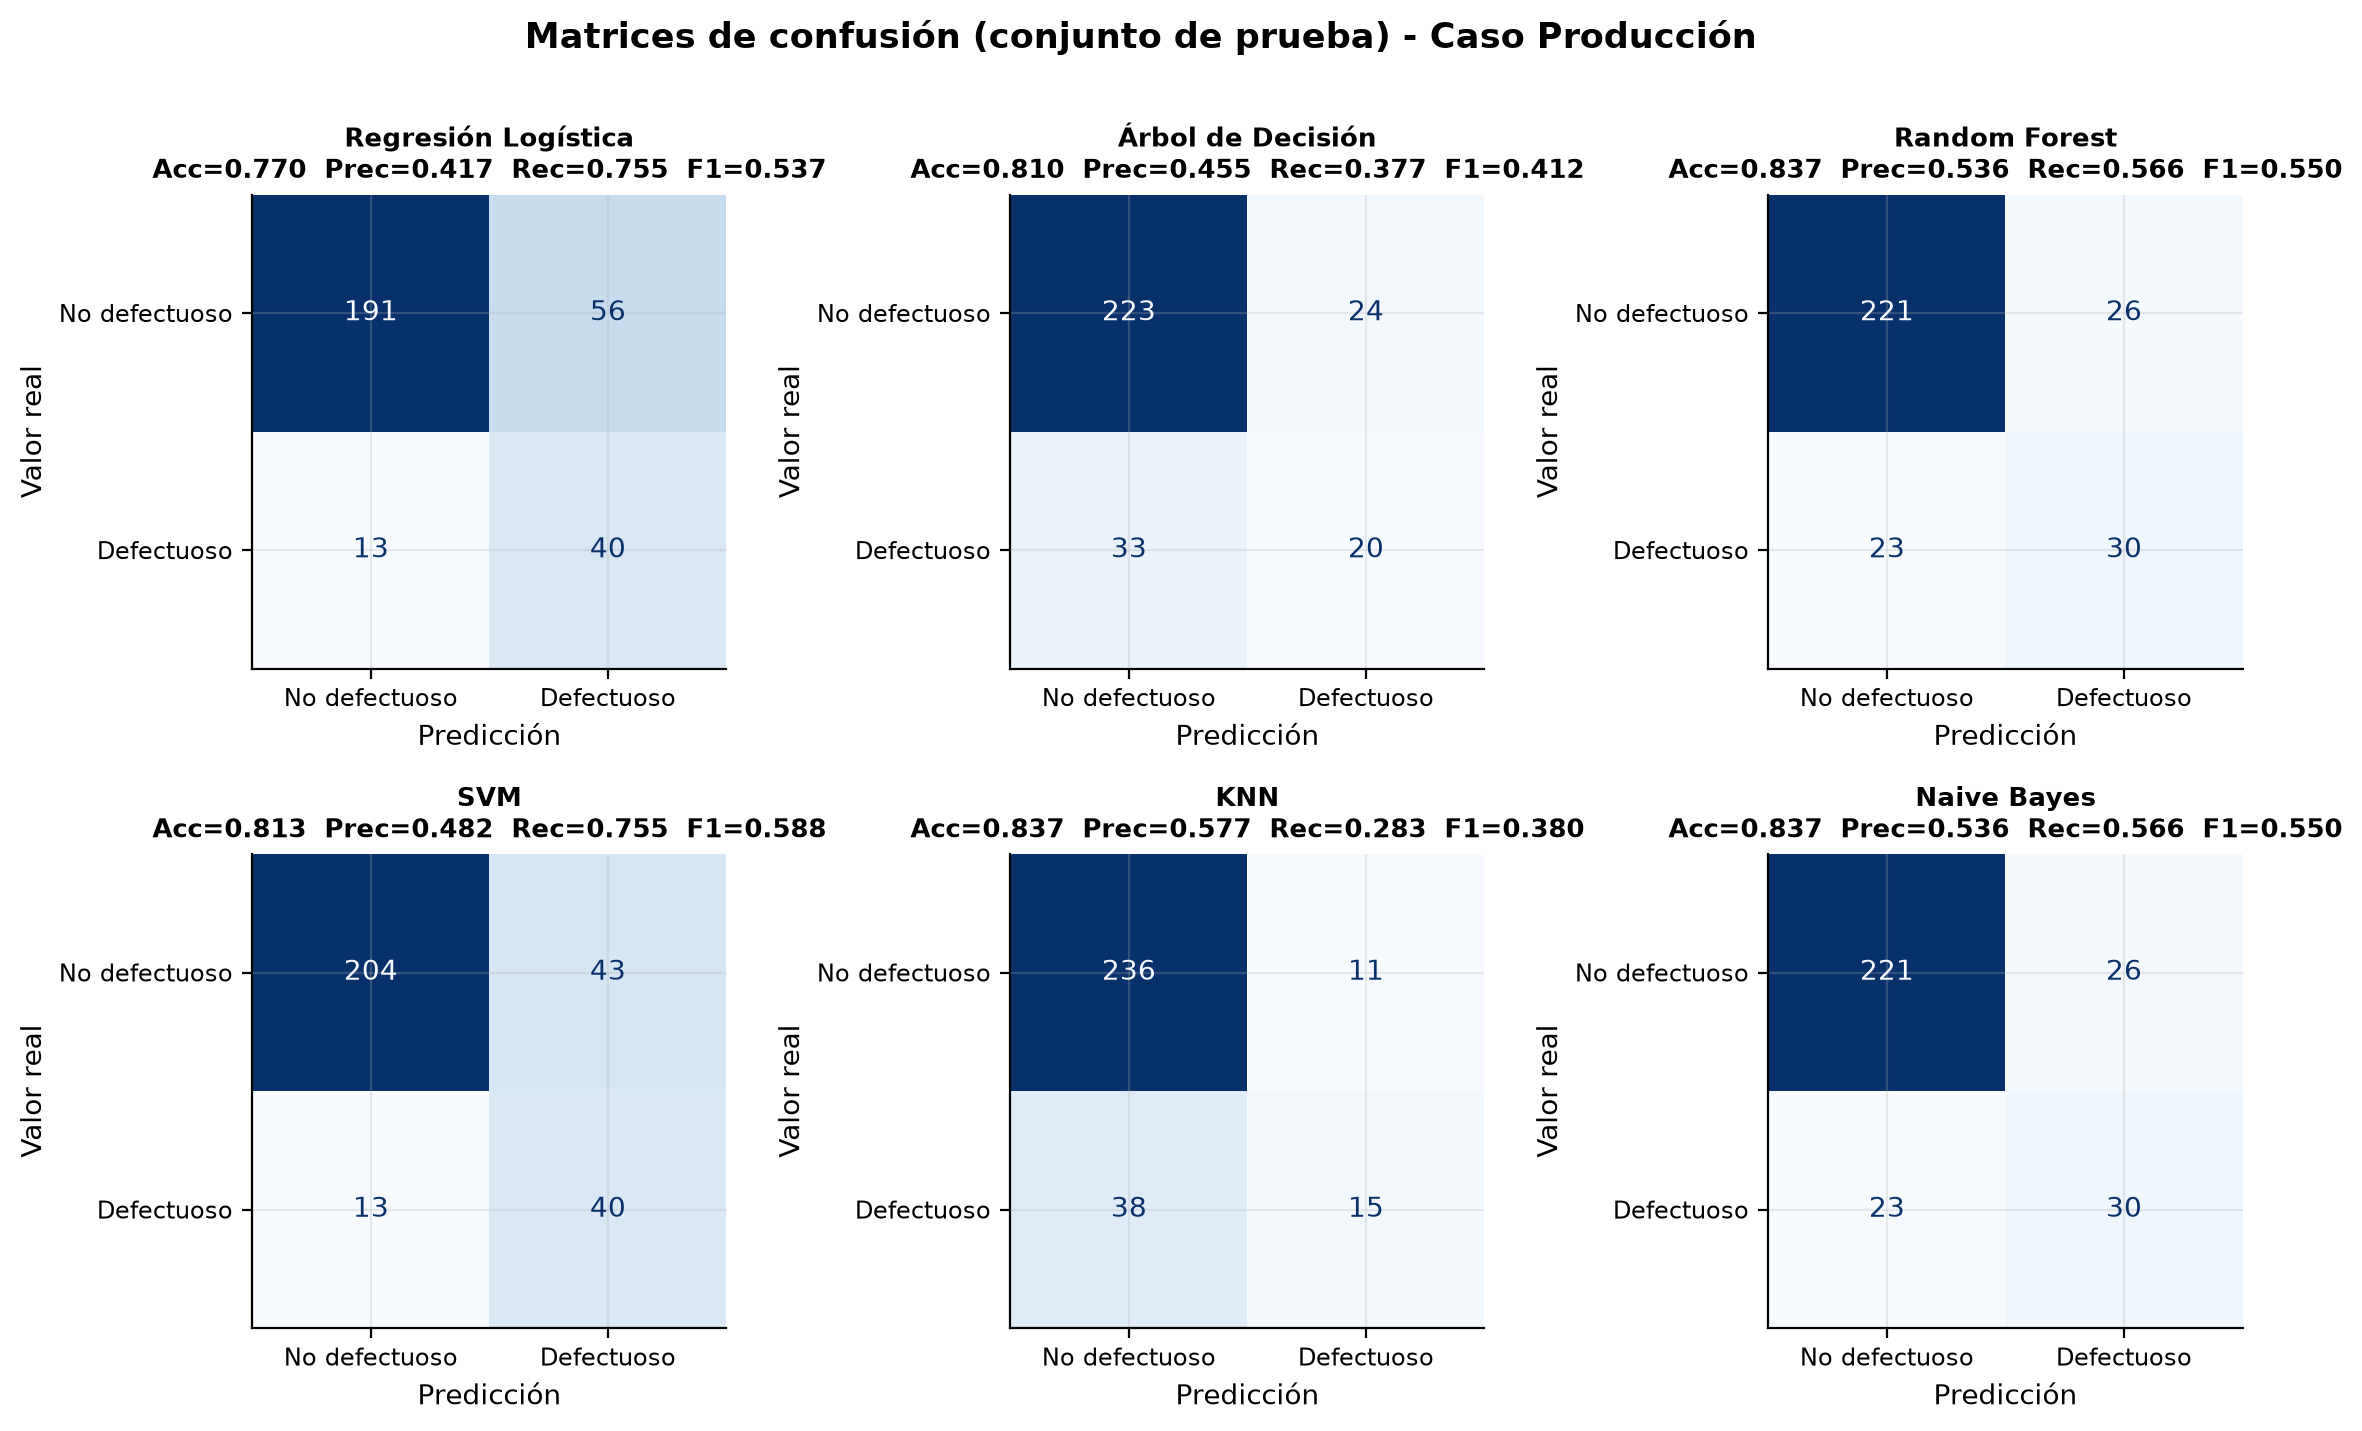

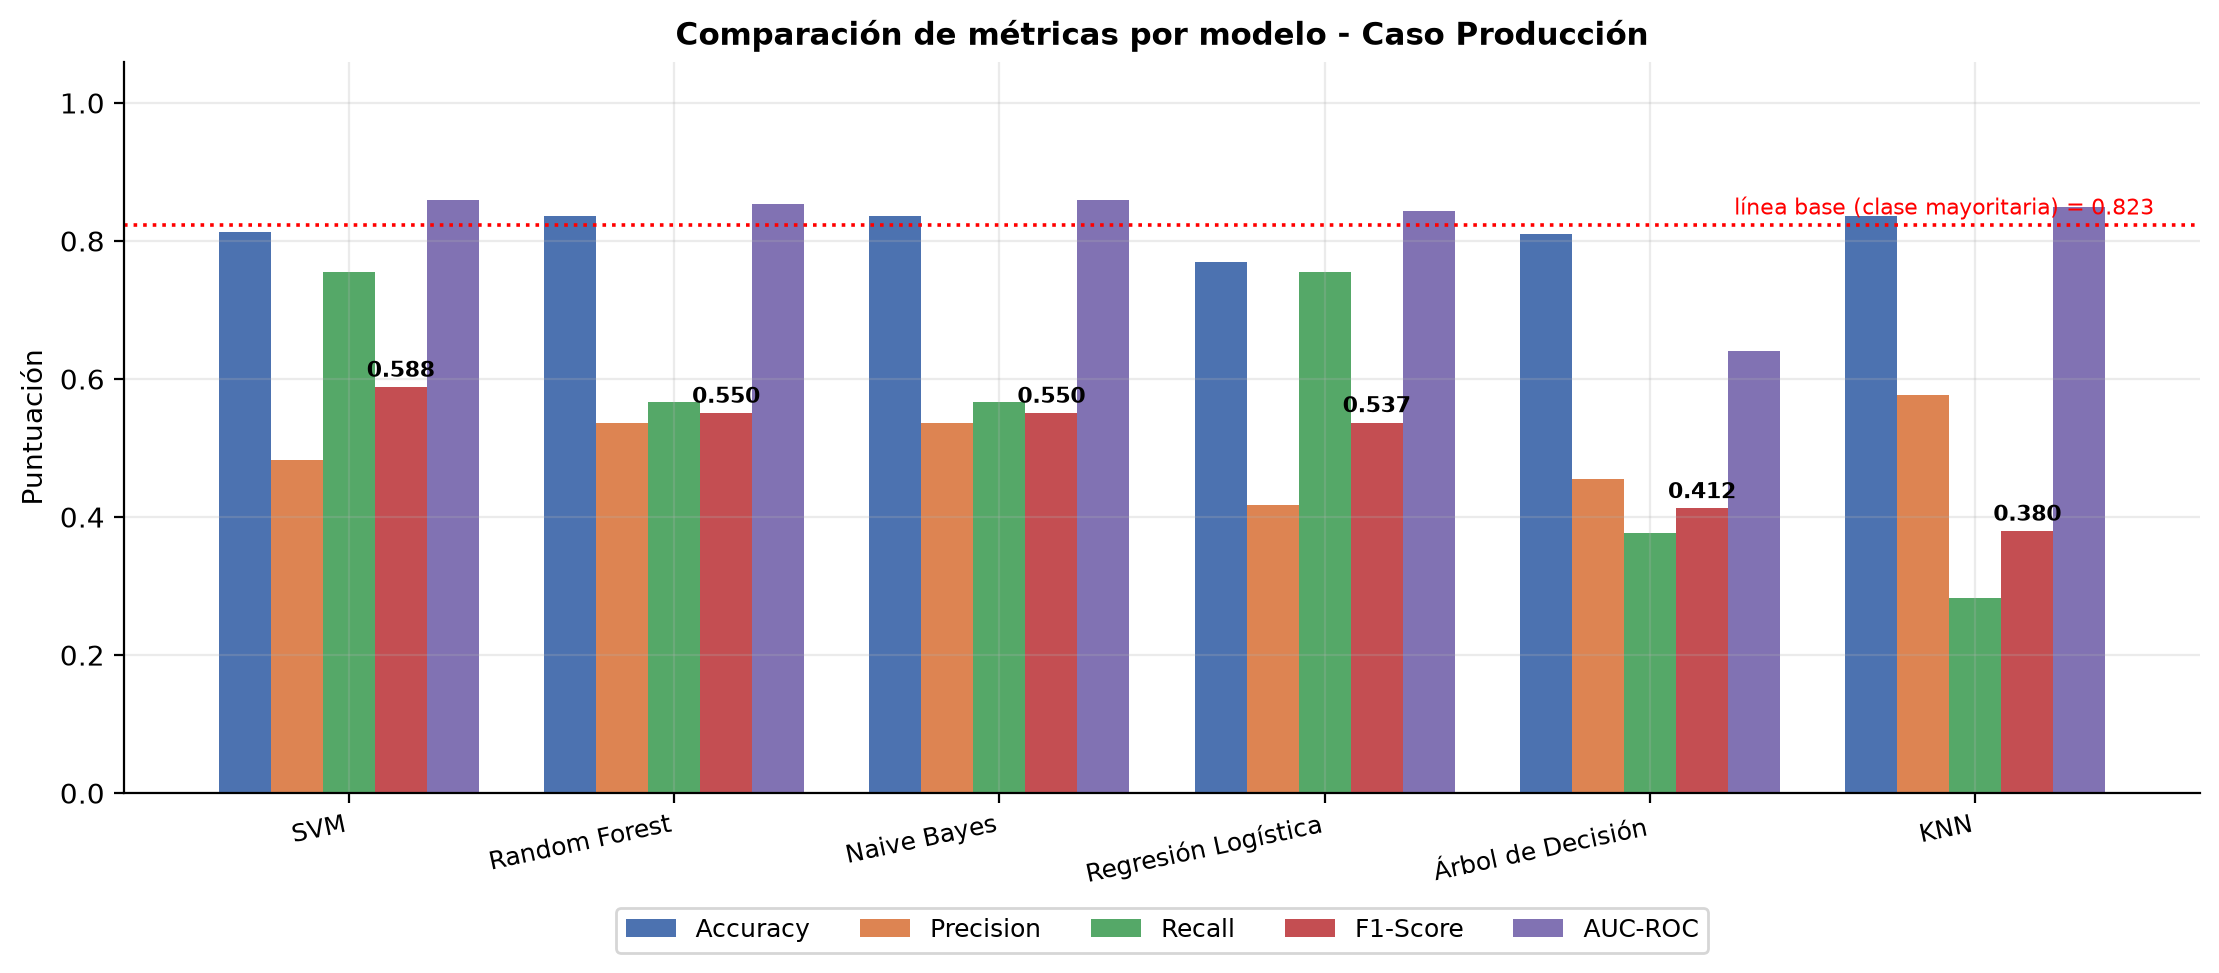

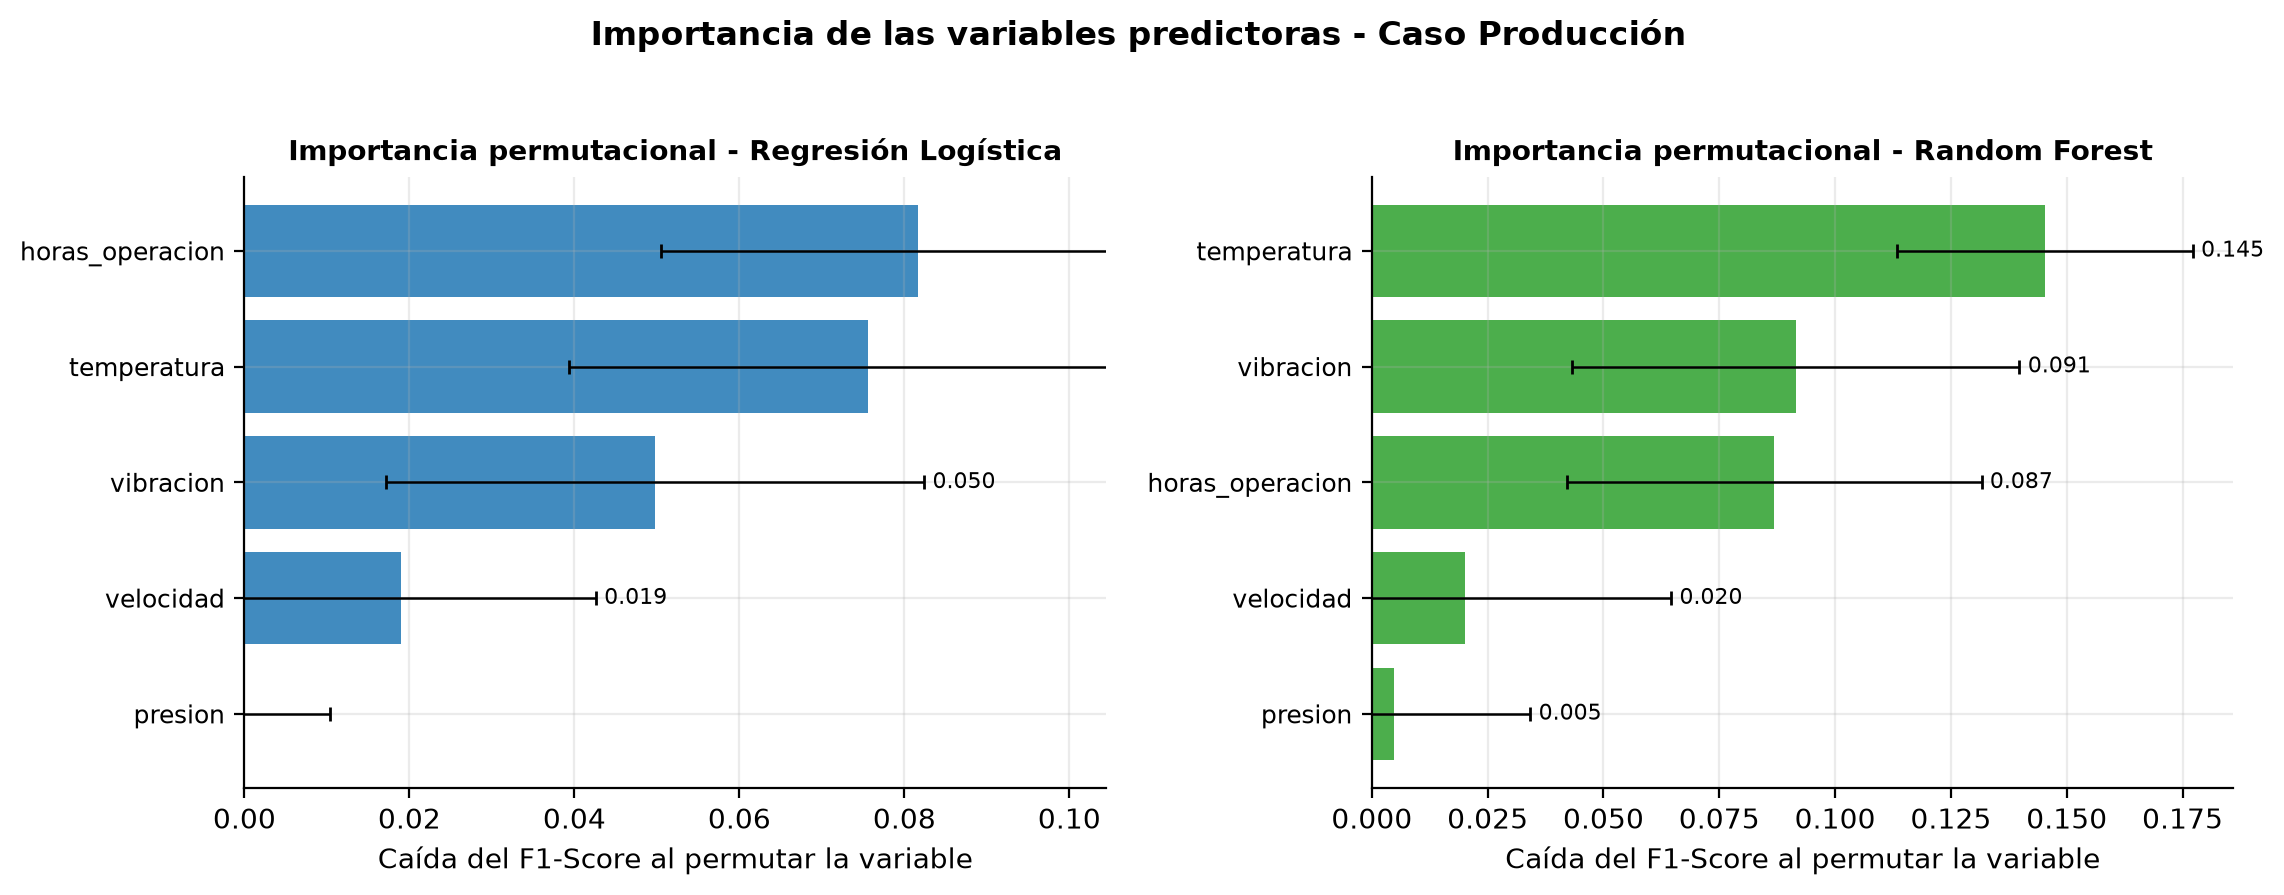

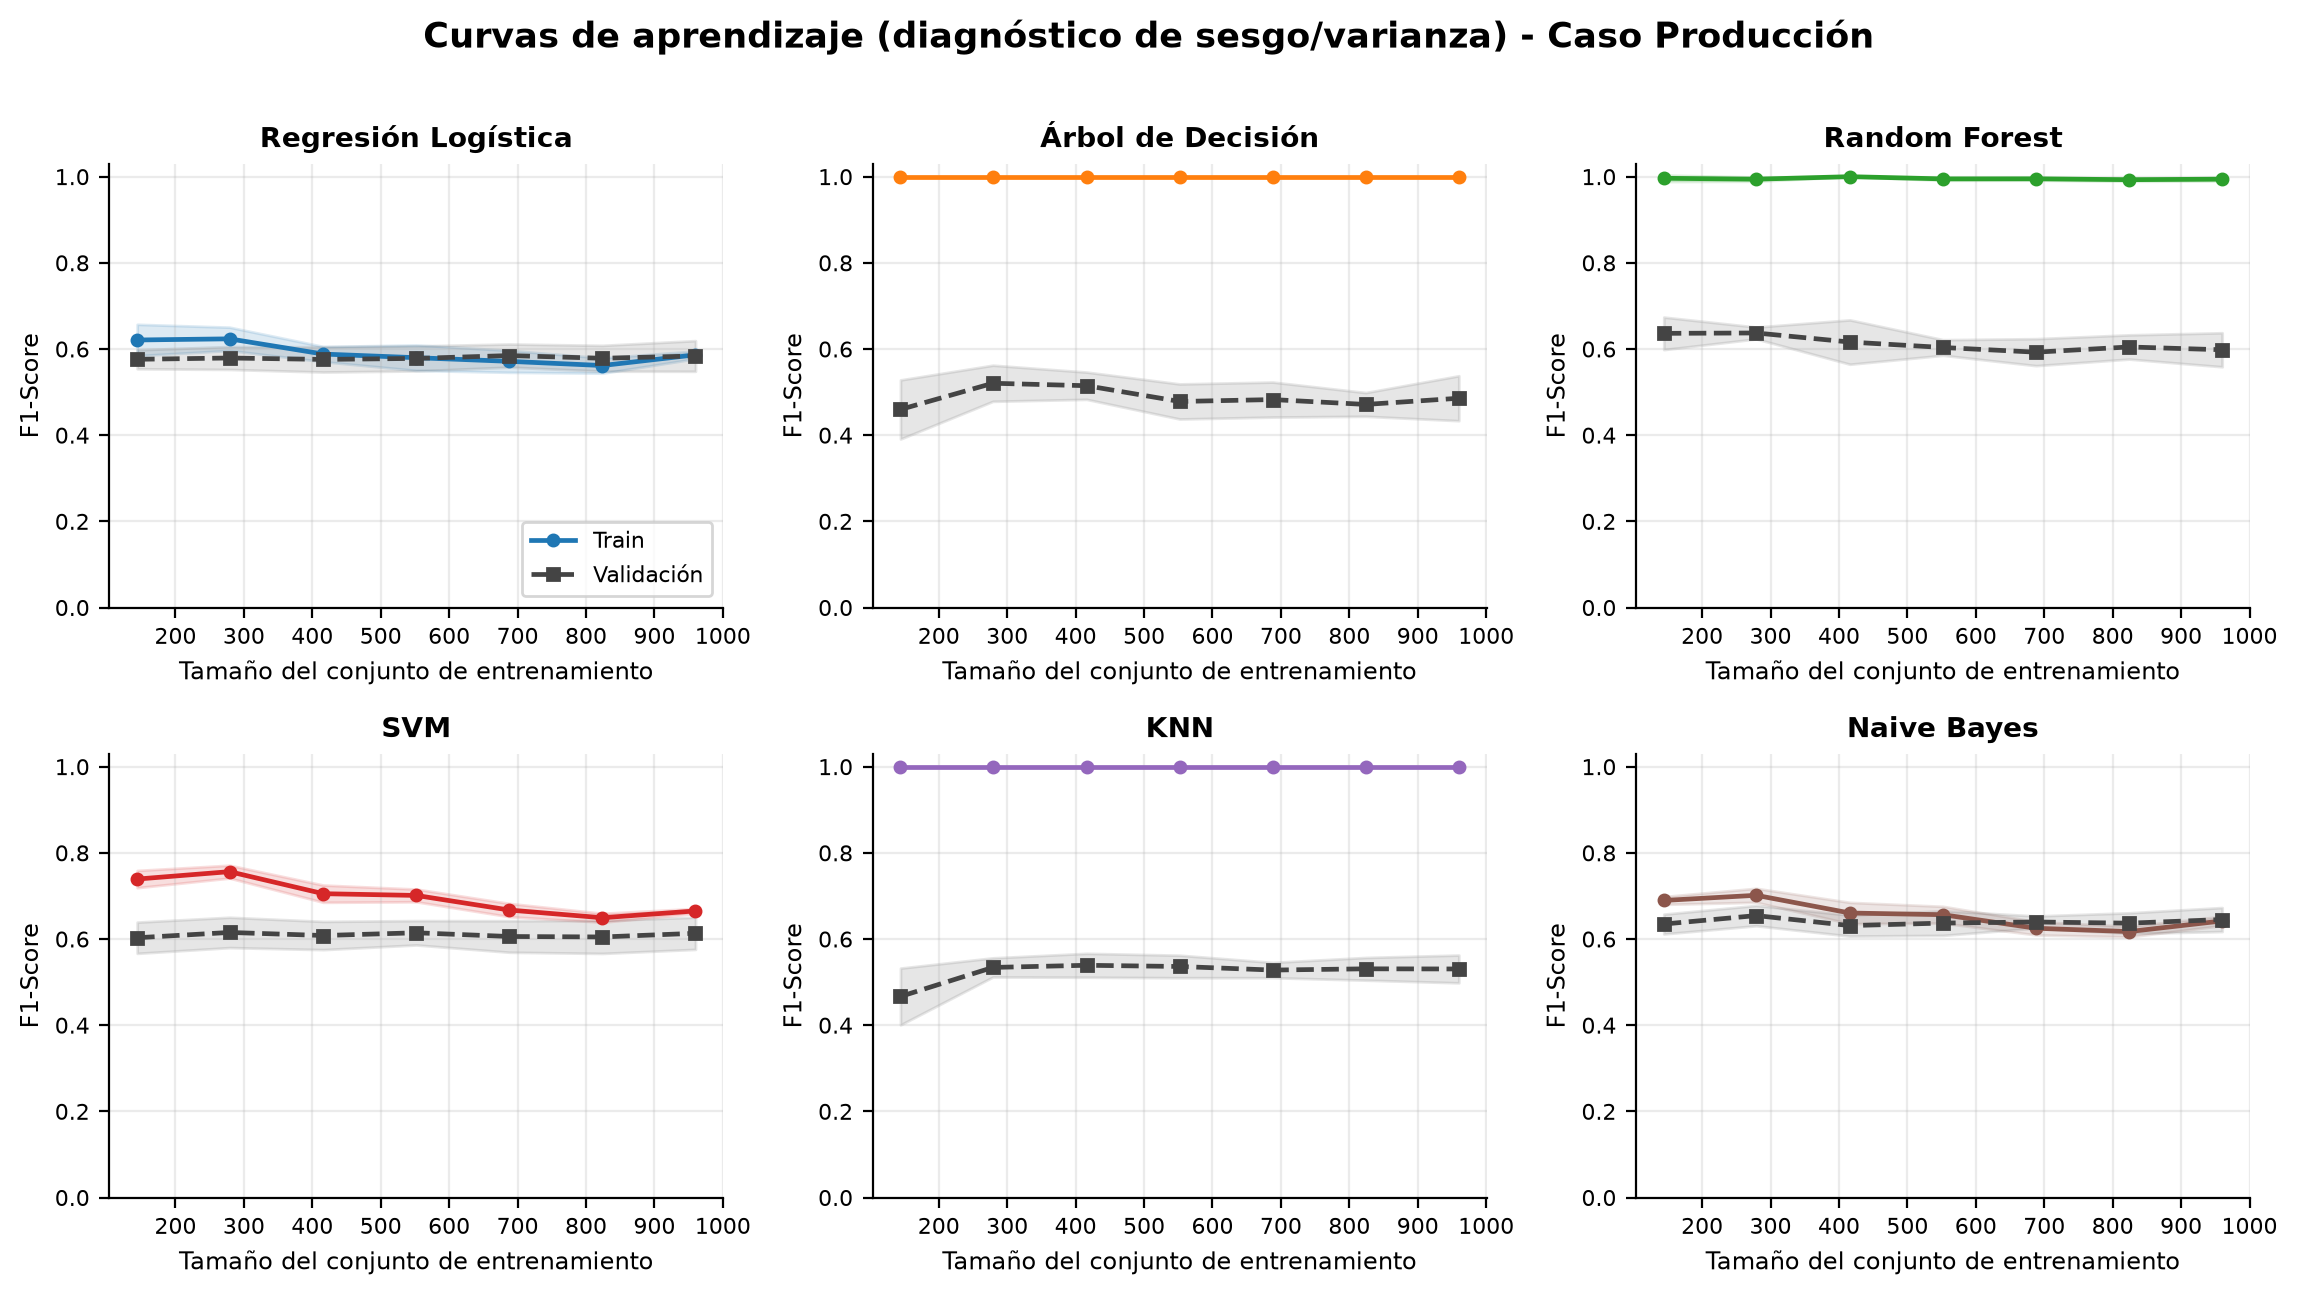

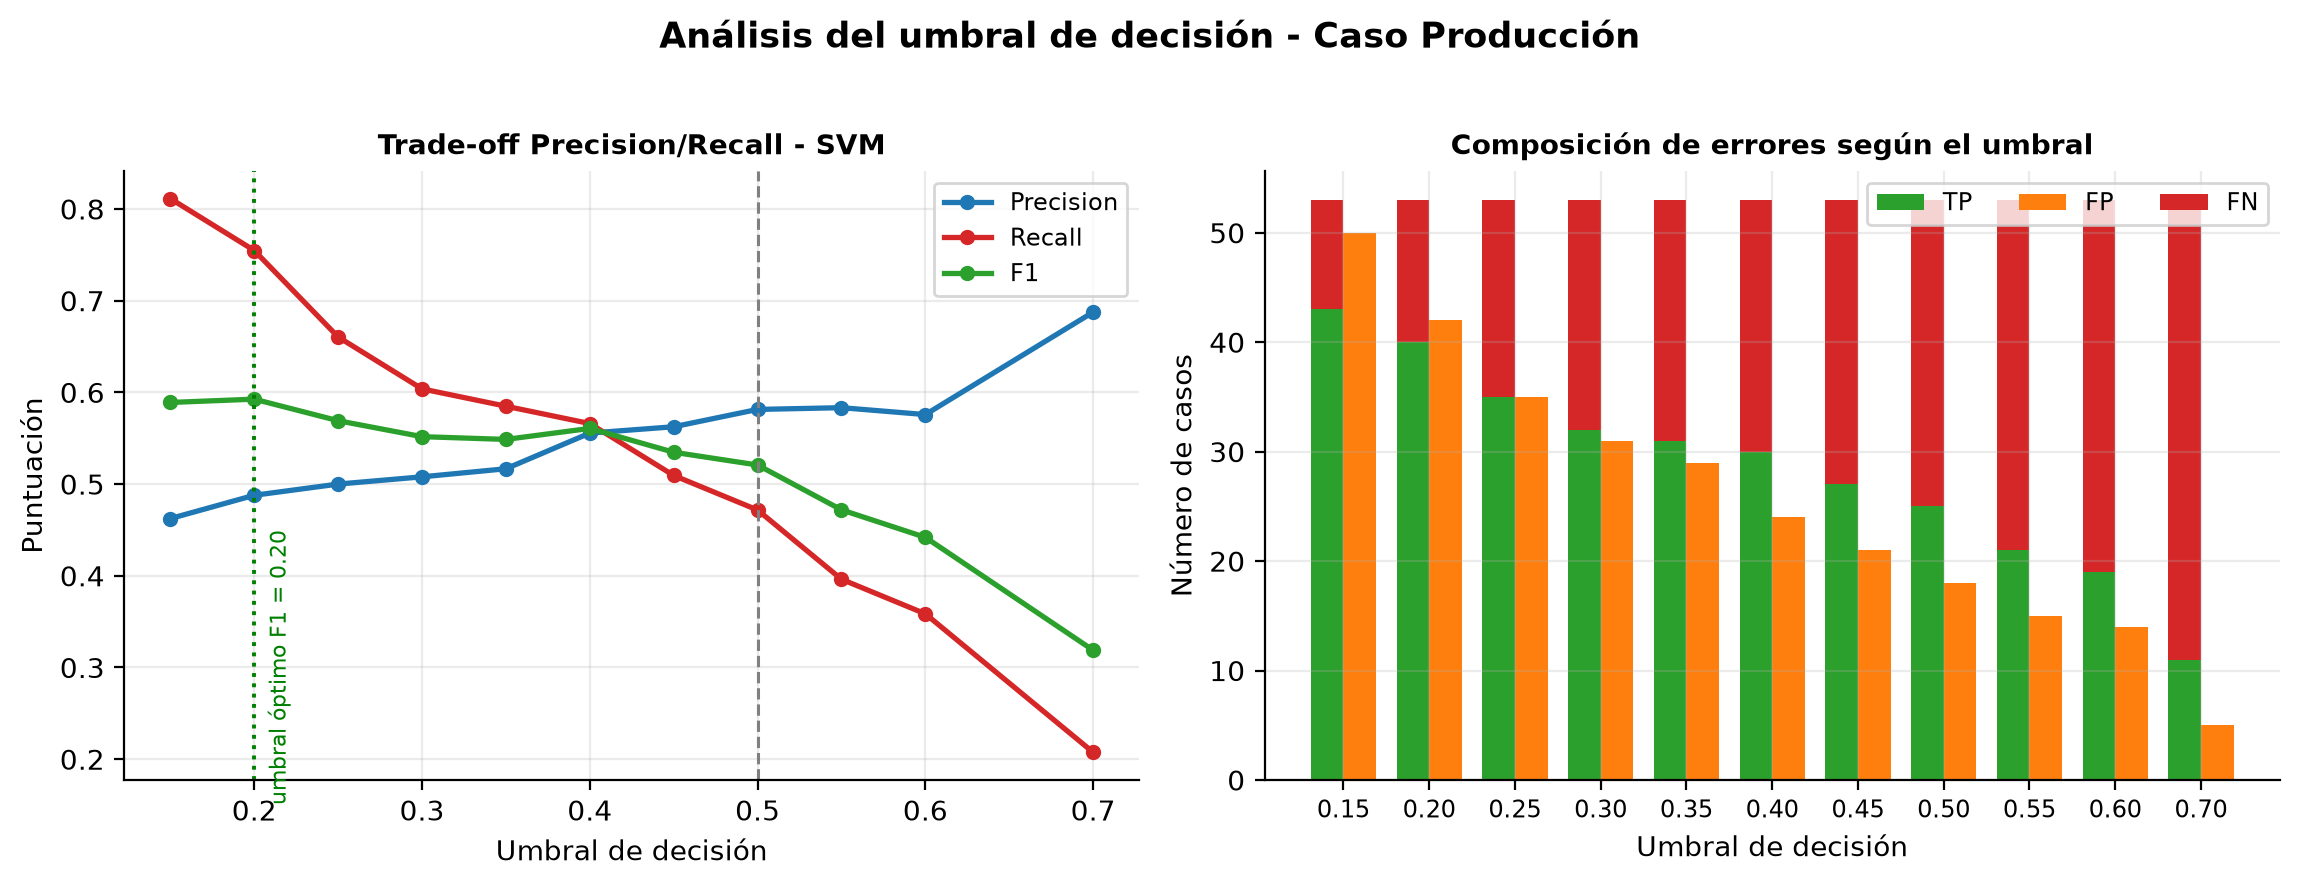

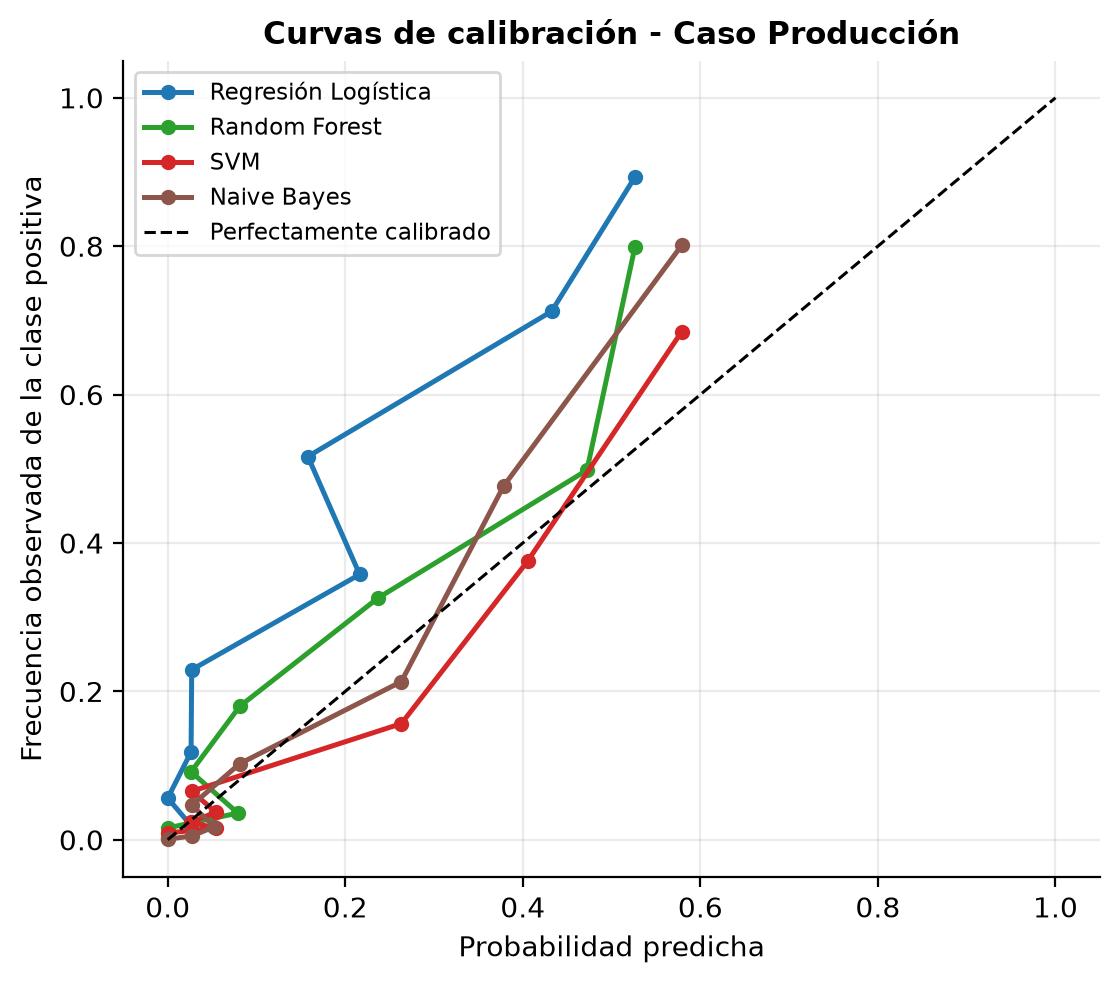

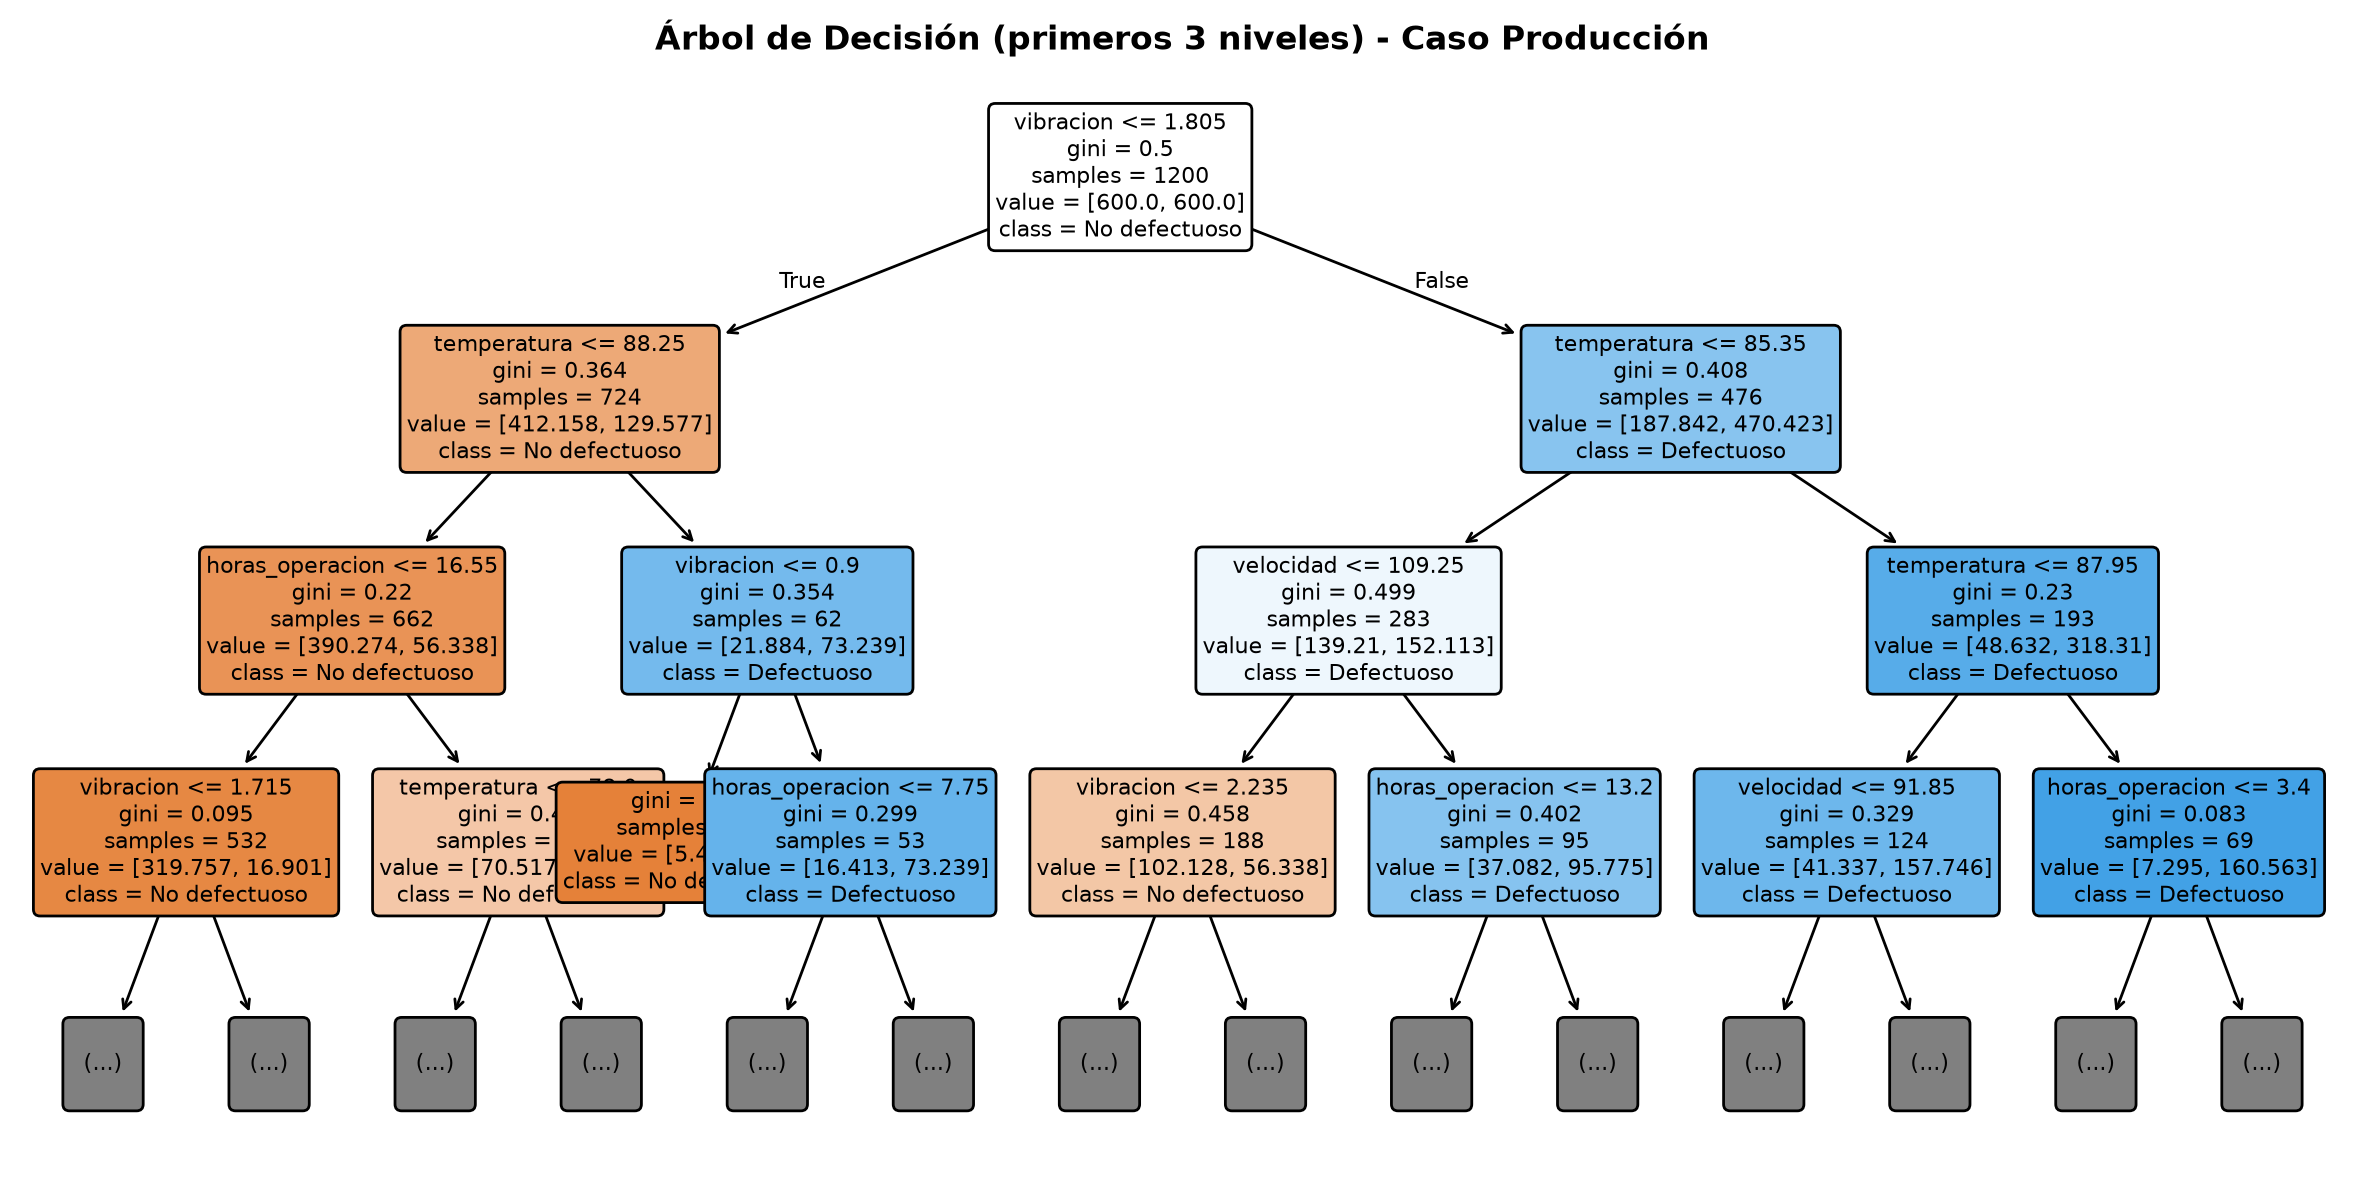

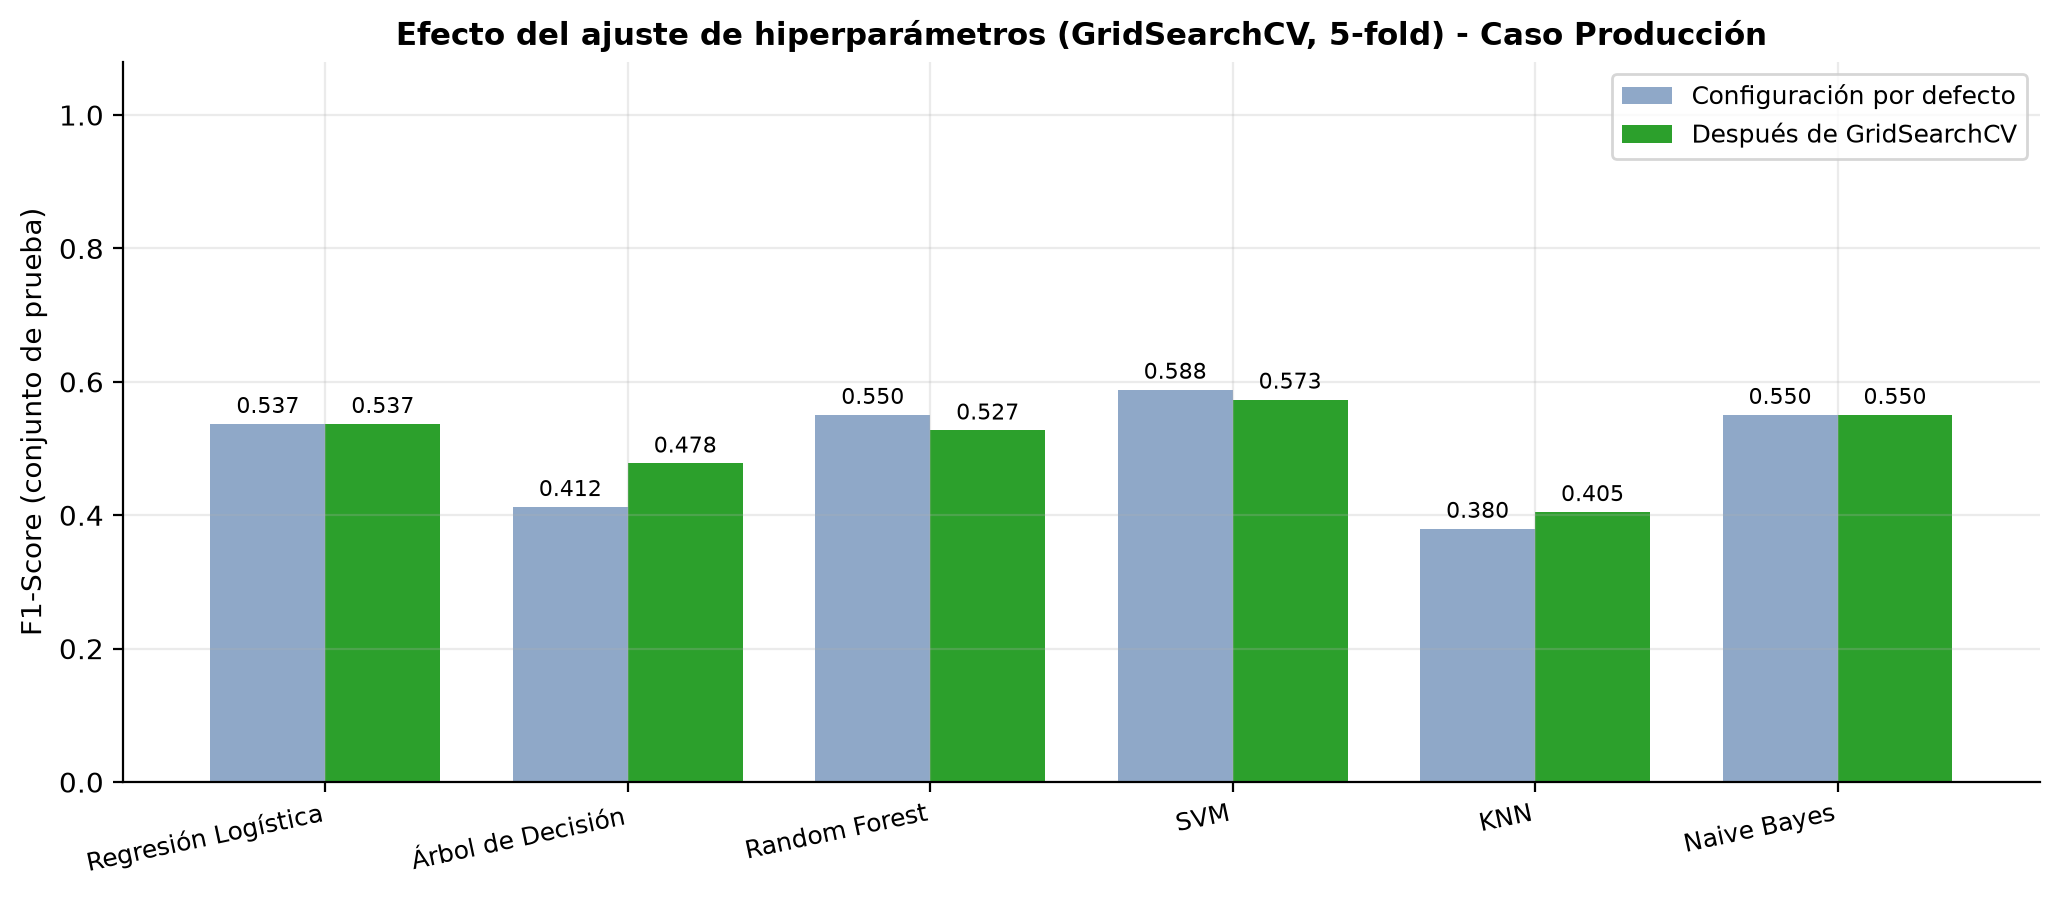

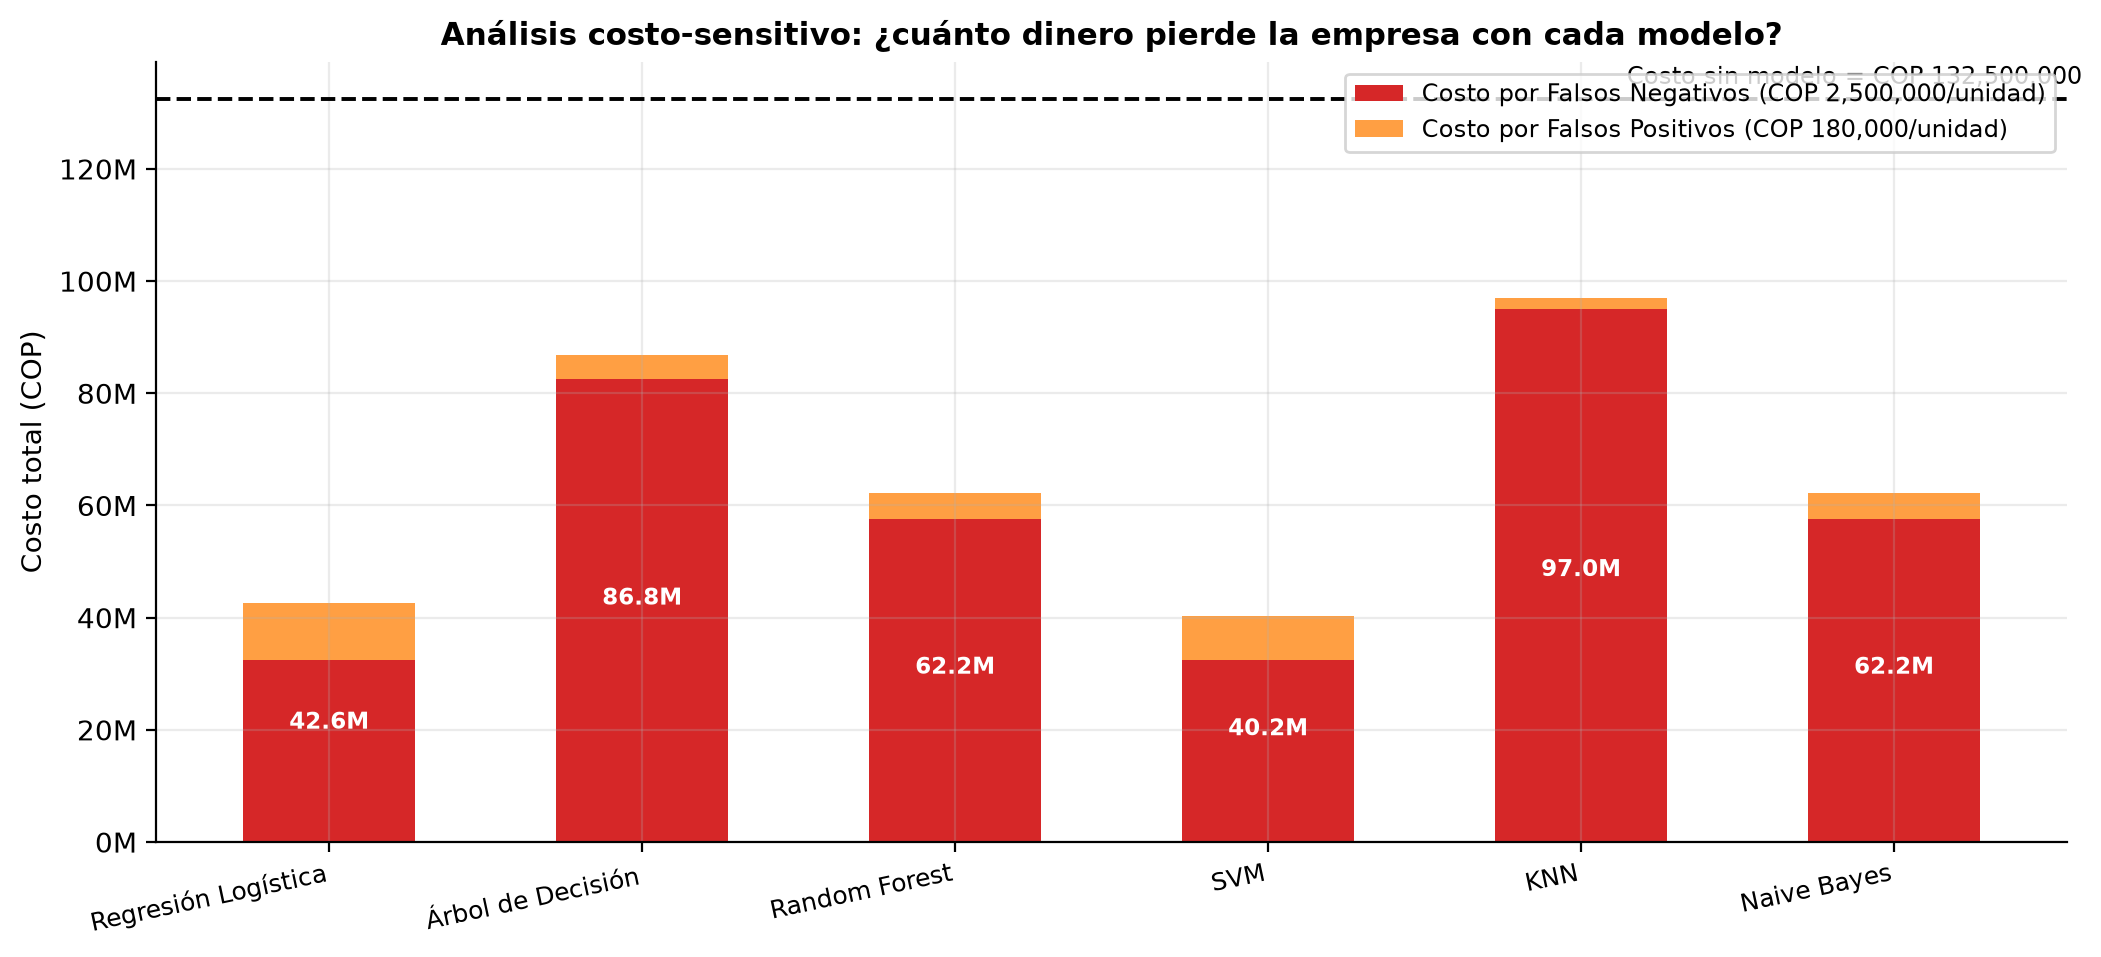

In [6]:
for f in sorted(DIR_FIGS.glob('prod_*.png')):
    display(Image(filename=str(f)))

## 4. Reportes de clasificación por modelo

In [7]:
for nombre, m in res.metricas.items():
    print('='*70); print(nombre); print('='*70); print(m['reporte'])

Regresión Logística
               precision    recall  f1-score   support

No defectuoso      0.936     0.773     0.847       247
   Defectuoso      0.417     0.755     0.537        53

     accuracy                          0.770       300
    macro avg      0.676     0.764     0.692       300
 weighted avg      0.844     0.770     0.792       300

Árbol de Decisión
               precision    recall  f1-score   support

No defectuoso      0.871     0.903     0.887       247
   Defectuoso      0.455     0.377     0.412        53

     accuracy                          0.810       300
    macro avg      0.663     0.640     0.650       300
 weighted avg      0.798     0.810     0.803       300

Random Forest
               precision    recall  f1-score   support

No defectuoso      0.906     0.895     0.900       247
   Defectuoso      0.536     0.566     0.550        53

     accuracy                          0.837       300
    macro avg      0.721     0.730     0.725       300
 weig

## 5. Umbral de decisión y costo económico

In [8]:
pd.DataFrame(res.extra['umbrales'])

,umbral,precision,recall,f1,accuracy,fp,fn,tp,tn,costo_total
0,0.15,0.4624,0.8113,0.5890,0.8000,50,10,43,197,34000000
1,0.20,0.4878,0.7547,0.5926,0.8167,42,13,40,205,40060000
2,0.25,0.5000,0.6604,0.5691,0.8233,35,18,35,212,51300000
3,0.30,0.5079,0.6038,0.5517,0.8267,31,21,32,216,58080000
4,0.35,0.5167,0.5849,0.5487,0.8300,29,22,31,218,60220000
5,0.40,0.5556,0.5660,0.5607,0.8433,24,23,30,223,61820000
6,0.45,0.5625,0.5094,0.5347,0.8433,21,26,27,226,68780000
7,0.50,0.5814,0.4717,0.5208,0.8467,18,28,25,229,73240000
8,0.55,0.5833,0.3962,0.4719,0.8433,15,32,21,232,82700000
9,0.60,0.5758,0.3585,0.4419,0.8400,14,34,19,233,87520000


In [9]:
pd.DataFrame(res.extra['costos']).T

,costo_total,costo_por_lote,costo_ahorrado_vs_baseline,costo_sin_modelo,costo_fn,costo_fp,moneda,positivos_en_test
Regresión Logística,42580000.0,141933.3,89920000.0,NaN,NaN,NaN,NaN,NaN
Árbol de Decisión,86820000.0,289400.0,45680000.0,NaN,NaN,NaN,NaN,NaN
Random Forest,62180000.0,207266.7,70320000.0,NaN,NaN,NaN,NaN,NaN
SVM,40240000.0,134133.3,92260000.0,NaN,NaN,NaN,NaN,NaN
KNN,96980000.0,323266.7,35520000.0,NaN,NaN,NaN,NaN,NaN
Naive Bayes,62180000.0,207266.7,70320000.0,NaN,NaN,NaN,NaN,NaN
_referencia,NaN,NaN,NaN,132500000,2500000,180000,COP,53


## 6. GridSearchCV (5 pliegues, scoring=F1)

In [10]:
pd.DataFrame(res.extra['grid_search']).T

,mejores_params,mejor_f1_cv,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_ap,tn,fp,fn,tp
Regresión Logística,{'clf__C': 1},0.5839,0.77,0.4167,0.7547,0.5369,0.8429,0.5779,191,56,13,40
Árbol de Decisión,"{'clf__max_depth': 3, 'clf__min_samples_leaf':...",0.5652,0.7667,0.3951,0.6038,0.4776,0.7804,0.4285,198,49,21,32
Random Forest,"{'clf__max_depth': 6, 'clf__min_samples_leaf':...",0.6326,0.7967,0.4474,0.6415,0.5271,0.8536,0.5601,205,42,19,34
SVM,"{'clf__C': 50, 'clf__gamma': 0.01}",0.6168,0.7967,0.4556,0.7736,0.5734,0.8711,0.6224,198,49,12,41
KNN,{'clf__n_neighbors': 7},0.5386,0.8333,0.5484,0.3208,0.4048,0.8265,0.5088,233,14,36,17
Naive Bayes,{'clf__var_smoothing': 1e-09},0.6452,0.8367,0.5357,0.566,0.5505,0.859,0.6001,221,26,23,30


## 7. Interpretación
* **SVM (RBF)**: mejor F1 (0.588) y menor costo; captura la no linealidad térmica.
* **KNN**: recall 0.283 → inaceptable cuando el falso negativo cuesta COP 2.5 M.
* Umbral 0.15 en SVM: recall 0.811 y costo de COP 34.0 M vs 73.2 M del umbral 0.50.
* Vibración y temperatura dominan la importancia permutacional.
